# Uji Validitas dan Reliabilitas Instrumen (Skala Likert)
Mata Kuliah Statistika dan Probabilitas — mengikuti *Modul Pengujian Validitas dan Reliabilitas Instrumen*.

Alur: unggah data → ubah jawaban Likert ke angka (1–5) → kelompokkan butir per dimensi → **uji validitas** (r hitung vs r tabel) → **uji reliabilitas** (Cronbach's alpha) → buang butir tidak valid dan uji ulang.

In [ ]:
import re
import pandas as pd
import numpy as np
from scipy import stats

## Langkah 1 — Unggah data
Di Google Colab jalankan sel ini lalu pilih file `.xlsx`. Di komputer sendiri, isi `nama_file` dengan nama berkas.

In [ ]:
try:
    from google.colab import files
    up = files.upload()
    nama_file = list(up.keys())[0]
except ImportError:           # dijalankan di luar Colab
    nama_file = "Kuesioner_Penggunaan_AI_dan_Lifestyle_Media_Sosial_Mahasiswa_Jawaban.xlsx"   # <- ganti dengan nama file Anda
print("File terbaca:", nama_file)

Saving Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx to Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx
File terbaca: Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx


## Langkah 2 — Baca data dan pisahkan butir
Kolom yang judulnya berformat `Nama Dimensi [teks pernyataan]` dibaca sebagai **butir**. Kolom lain (Timestamp, Score, Kelas, Jenis Kelamin, jumlah platform AI, durasi gadget, dst.) dianggap data demografi dan tidak ikut diuji. Cara ini lebih aman daripada memotong lima kolom pertama, karena pada ekspor Google Forms ada kolom non-butir di tengah (mis. durasi gadget).

In [ ]:
df = pd.read_excel(nama_file)

adalah_butir = [bool(re.match(r".*\[.*\]\s*$", str(k), flags=re.S)) for k in df.columns]
butir = df.loc[:, adalah_butir]
demografi = df.loc[:, [not a for a in adalah_butir]]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))
print("Kolom bukan butir (tidak diuji):")
for k in demografi.columns:
    print("  -", k[:80])

Jumlah responden : 30
Jumlah butir     : 29
Data kosong      : 0
Kolom bukan butir (tidak diuji):
  - Timestamp
  - Kelas
  - Jenis Kelamin
  - Berapa jumlah platform AI yang rutin kamu gunakan untuk membantu menyelesaikan t
  - Berapa jumlah platform AI yang kamu gunakan dengan berlangganan premium (berbaya
  - Berapa durasi rata-rata kamu menggunakan gadget per hari, mulai dari kebutuhan h


## Langkah 3 — Ubah jawaban Likert menjadi angka
Sangat Setuju = 5 … Sangat Tidak Setuju = 1. Penulisan label dinormalkan (spasi dan huruf besar/kecil) supaya tidak ada sel yang gagal dibaca. Sel yang sudah berupa angka 1–5 dibiarkan.

In [ ]:
skala = {"sangat tidak setuju": 1, "sts": 1,
         "tidak setuju": 2, "ts": 2,
         "netral": 3, "n": 3,
         "setuju": 4, "s": 4,
         "sangat setuju": 5, "ss": 5}

def ke_angka(v):
    if pd.isna(v):
        return np.nan
    if isinstance(v, (int, float, np.integer, np.floating)):
        return float(v)
    teks = re.sub(r"\s+", " ", str(v)).strip().lower()
    teks = re.sub(r"\s*\(.*?\)\s*$", "", teks)          # buang "(S)", "(SS)", dst.
    if teks in skala:
        return float(skala[teks])
    kode = re.search(r"\((.*?)\)\s*$", str(v))
    return float(skala.get(kode.group(1).strip().lower(), np.nan)) if kode else np.nan

num = butir.apply(lambda kol: kol.map(ke_angka))

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
print("Rentang nilai:", num.min().min(), "sampai", num.max().max())
num.head()

Sel yang gagal dikonversi: 0
Rentang nilai: 1.0 sampai 5.0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI hampir setiap kali mendapatkan tugas atau projek kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari penyelesaian soal atau permasalahan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi saat mengerjakan tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk memahami materi kuliah yang belum saya kuasai.],"Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk menyusun atau memperbaiki tulisan dalam tugas kuliah, misalnya laporan atau makalah.]",Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk membuat atau memperbaiki kode program pada tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan lebih dari satu platform AI untuk menyelesaikan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan menyelesaikan tugas kuliah tanpa bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung langsung mengikuti jawaban AI tanpa mempertimbangkan sumber lain.],...,Kebiasaan penggunaan teknologi digital [Konsentrasi saya mudah terganggu oleh gadget ketika sedang mengerjakan tugas kuliah.],Prokrastinasi akademik [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik [Saya sering menunda tugas karena merasa tugas tersebut dapat diselesaikan dengan cepat menggunakan AI.],Prokrastinasi akademik [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik [Saya sering harus mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas dengan hasil tugas yang dikerjakan terburu-buru menjelang deadline.],Respon emosional [Saya merasa gelisah ketika mengingat tugas yang belum saya kerjakan.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,2.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,2.0,2.0,...,1.0,2.0,2.0,2.0,2.0,4.0,4.0,4.0,4.0,4.0
1,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,2.0,...,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0
2,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,4.0,4.0,...,5.0,2.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
3,4.0,5.0,5.0,5.0,4.0,4.0,4.0,4.0,2.0,2.0,...,4.0,4.0,2.0,5.0,4.0,4.0,4.0,2.0,5.0,4.0
4,5.0,4.0,5.0,5.0,5.0,4.0,5.0,5.0,4.0,1.0,...,4.0,1.0,2.0,1.0,2.0,5.0,5.0,4.0,4.0,4.0


**Data numerik** disimpan ke Excel (kolom demografi + semua butir sudah berupa angka) sebagai bukti langkah konversi.

In [ ]:
numerik_lengkap = pd.concat([demografi, num], axis=1)
numerik_lengkap.to_excel("data_numerik_likert.xlsx", index=False)
print("Tersimpan: data_numerik_likert.xlsx")

Tersimpan: data_numerik_likert.xlsx


## Langkah 4 — Kelompokkan butir per dimensi
Nama dimensi diambil dari teks sebelum tanda `[` (spasi dan titik di ujung dibuang; salah ketik diperbaiki lewat `KOREKSI_NAMA`).

In [ ]:
# perbaiki salah ketik pada judul dimensi
KOREKSI_NAMA = {"Rsspon emosional": "Respon emosional"}
def nama_dimensi(kolom):
    m = re.match(r"^(.*?)\s*\[", kolom, flags=re.S)
    nama = (m.group(1) if m else "Semua butir").strip().rstrip(".").strip()
    return KOREKSI_NAMA.get(nama, nama)

def kelompokkan(num):
    dimensi = {}
    for kolom in num.columns:
        dimensi.setdefault(nama_dimensi(kolom), []).append(kolom)
    return dimensi

dimensi = kelompokkan(num)
for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


## Langkah 5 — Uji validitas (korelasi Pearson butir–total)
- r tabel bergantung pada **n** dan **α = 0,05** (df = n − 2); untuk n = 30, r tabel = 0,361.
- r hitung **>** r tabel → **valid**; r hitung **≤** r tabel → **tidak valid**.
- *Corrected r* = korelasi butir dengan (total − butir itu sendiri), pembanding yang lebih ketat (batas 0,30).

In [ ]:
def r_tabel_dari(n, alpha=0.05):
    t = stats.t.ppf(1 - alpha / 2, n - 2)
    return t / np.sqrt((n - 2) + t**2)

def uji_validitas(num, dimensi):
    r_tab = r_tabel_dari(len(num))
    baris = []
    for nama, daftar in dimensi.items():
        x = num[daftar]
        total = x.sum(axis=1)
        for i, kolom in enumerate(daftar, 1):
            r, p = stats.pearsonr(x[kolom], total)
            rk, _ = stats.pearsonr(x[kolom], total - x[kolom]) if len(daftar) > 1 else (np.nan, None)
            baris.append({"Dimensi": nama, "Butir": f"B{i}", "Kolom asli": kolom,
                          "r hitung": round(r, 3), "Corrected r": round(rk, 3),
                          "p-value": round(p, 4),
                          "Keterangan": "Valid" if r > r_tab else "Tidak valid"})
    return pd.DataFrame(baris), r_tab

tabel_validitas, r_tabel = uji_validitas(num, dimensi)
print(f"n = {len(num)} | r tabel (α=0,05; df={len(num)-2}) = {r_tabel:.3f}")
tabel_validitas.drop(columns="Kolom asli")

n = 30 | r tabel (α=0,05; df=28) = 0.361


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.790,0.668,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.691,0.585,0.0000,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.627,0.481,0.0002,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.554,0.424,0.0015,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.722,0.495,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.800,0.723,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.654,0.548,0.0001,Valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.710,0.605,0.0000,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.780,0.685,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.710,0.617,0.0000,Valid


In [ ]:
ringkas = tabel_validitas.groupby("Dimensi")["Keterangan"].value_counts().unstack(fill_value=0)
ringkas.loc["TOTAL"] = ringkas.sum()
print(ringkas)
print("\nButir tidak valid:")
tabel_validitas[tabel_validitas["Keterangan"] == "Tidak valid"].drop(columns="Kolom asli")

Keterangan                                          Valid
Dimensi                                                  
Aspek Psikologis penggunaan AI pada tugas atau ...      7
Kebiasaan penggunaan teknologi digital                  6
Penggunaan AI pada tugas atau projek kuliah             7
Prokrastinasi akademik                                  4
Respon emosional                                        5
TOTAL                                                  29

Butir tidak valid:


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan


## Langkah 6 — Uji reliabilitas (Cronbach's alpha, per dimensi)
α ≥ 0,70 → reliabel; α < 0,70 → tidak reliabel (kategori lengkap: ≥ 0,90 sangat baik, 0,80–0,89 baik, 0,70–0,79 reliabel).
*Alpha jika butir dihapus* lebih tinggi dari α dimensi → butir itu melemahkan konsistensi.

In [ ]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

def uji_reliabilitas(num, dimensi):
    hasil, dihapus = [], []
    for nama, daftar in dimensi.items():
        x = num[daftar]
        a = cronbach_alpha(x)
        hasil.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                      "Cronbach's alpha": round(a, 3), "Kategori": kategori(a)})
        for i, kolom in enumerate(daftar, 1):
            if len(daftar) > 2:
                dihapus.append({"Dimensi": nama, "Butir": f"B{i}",
                                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3)})
    return pd.DataFrame(hasil), pd.DataFrame(dihapus)

tabel_reliabilitas, tabel_alpha_dihapus = uji_reliabilitas(num, dimensi)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.799,Reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.886,Baik
2,Kebiasaan penggunaan teknologi digital,6,0.890,Baik
3,Prokrastinasi akademik,4,0.860,Baik
4,Respon emosional,5,0.928,Sangat baik


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.744
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.768
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.782
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.791
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.808
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.746
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.775
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.879
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.869
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.877


## Langkah 7 — Tindakan untuk butir tidak valid
Butir yang tidak valid **dibuang**, lalu Langkah 4–6 diulang pada data yang tersisa. Pertimbangkan juga isi butirnya, jangan hanya mengejar angka.
Sel di bawah membuang semua butir tidak valid, lalu membandingkan alpha sebelum dan sesudah.

In [ ]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")
dibuang = tabel_validitas.loc[tabel_validitas["Keterangan"] == "Tidak valid", "Kolom asli"].tolist()
print("Butir dibuang:", len(dibuang))

num2 = num.drop(columns=dibuang)
dimensi2 = kelompokkan(num2)
tabel_validitas2, r_tabel2 = uji_validitas(num2, dimensi2)
tabel_reliabilitas2, tabel_alpha_dihapus2 = uji_reliabilitas(num2, dimensi2)

print("Validitas setelah butir dibuang (semua harus Valid):")
print(tabel_validitas2["Keterangan"].value_counts().to_string())
perbandingan = tabel_reliabilitas.merge(tabel_reliabilitas2, on="Dimensi", how="left",
                                        suffixes=(" (sebelum)", " (sesudah)"))
perbandingan[["Dimensi", "Jumlah butir (sebelum)", "Cronbach's alpha (sebelum)",
              "Jumlah butir (sesudah)", "Cronbach's alpha (sesudah)", "Kategori (sesudah)"]]

Butir dibuang: 0
Validitas setelah butir dibuang (semua harus Valid):
Keterangan
Valid    29


,Dimensi,Jumlah butir (sebelum),Cronbach's alpha (sebelum),Jumlah butir (sesudah),Cronbach's alpha (sesudah),Kategori (sesudah)
0,Penggunaan AI pada tugas atau projek kuliah,7,0.799,7,0.799,Reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.886,7,0.886,Baik
2,Kebiasaan penggunaan teknologi digital,6,0.890,6,0.890,Baik
3,Prokrastinasi akademik,4,0.860,4,0.860,Baik
4,Respon emosional,5,0.928,5,0.928,Sangat baik


## Langkah 8 — Latihan modul: corrected r dan ukuran sampel

In [ ]:
# Latihan 2: jumlah butir valid menurut r hitung vs corrected r >= 0,30
v_r = int((tabel_validitas["r hitung"] > r_tabel).sum())
v_c = int((tabel_validitas["Corrected r"] >= 0.30).sum())
print(f"Valid menurut r hitung > r tabel : {v_r} dari {len(tabel_validitas)}")
print(f"Valid menurut corrected r >= 0,30: {v_c} dari {len(tabel_validitas)}")

# Latihan 4: pengaruh ukuran sampel (subset acak 20 responden)
sub = num.sample(20, random_state=1)
tv_sub, rt_sub = uji_validitas(sub, dimensi)
print(f"\nSubset n=20: r tabel = {rt_sub:.3f}, butir valid = {(tv_sub['Keterangan']=='Valid').sum()} dari {len(tv_sub)}")

Valid menurut r hitung > r tabel : 29 dari 29
Valid menurut corrected r >= 0,30: 29 dari 29

Subset n=20: r tabel = 0.444, butir valid = 28 dari 29


## Langkah 9 — Simpan hasil sebagai lampiran

In [ ]:
with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.drop(columns="Kolom asli").to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_validitas2.drop(columns="Kolom asli").to_excel(w, sheet_name="Validitas setelah dibuang", index=False)
    perbandingan.to_excel(w, sheet_name="Alpha sebelum-sesudah", index=False)
try:
    files.download("hasil_uji_validitas_reliabilitas.xlsx")
    files.download("data_numerik_likert.xlsx")
except NameError:
    print("Tersimpan di folder kerja.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
dimensi_laporan = {k: v for k, v in dimensi.items()
                   if k.startswith(("Penggunaan AI", "Aspek Psikologis"))}

In [16]:
dimensi_laporan = {k: v for k, v in dimensi.items()
                   if k.startswith(("Kebiasaan", "Prokrastinasi", "Respon"))}

Kebiasaan penggunaan teknologi digital


,STS,TS,N,S,SS
B1,5,2,0,10,13
B2,4,6,0,11,9
B3,6,6,0,8,10
B4,6,7,0,6,11
B5,3,6,0,4,17
B6,4,5,0,7,14


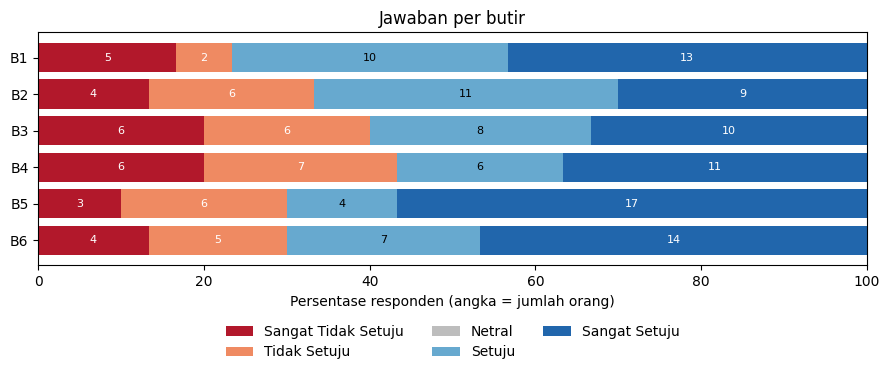

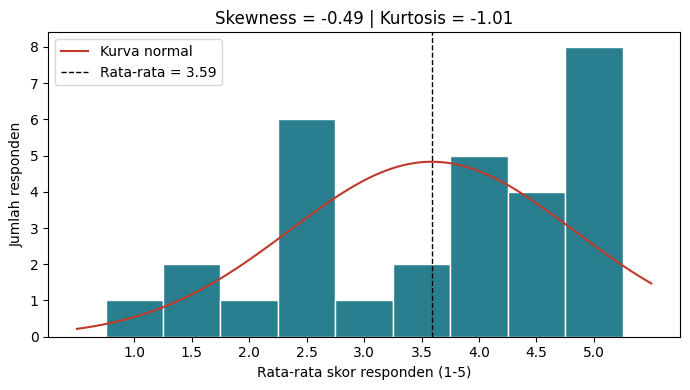

Rata-rata skor 3.59 (SD 1.24) | skewness -0.487 | kurtosis -1.015
Prokrastinasi akademik


,STS,TS,N,S,SS
B1,9,7,0,8,6
B2,8,9,0,5,8
B3,8,6,0,3,13
B4,5,8,1,7,9


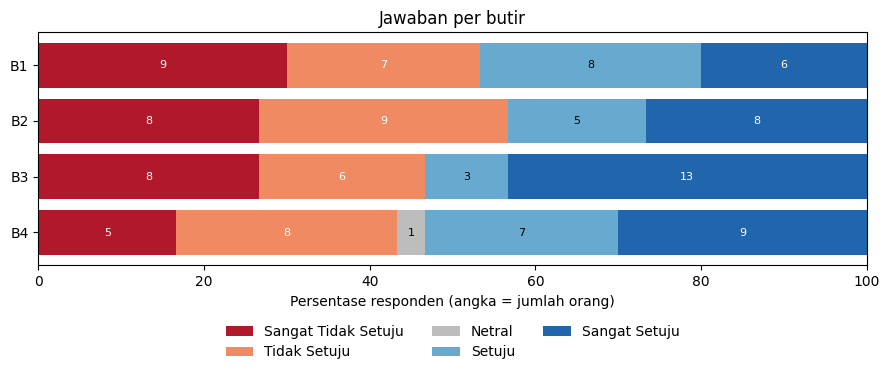

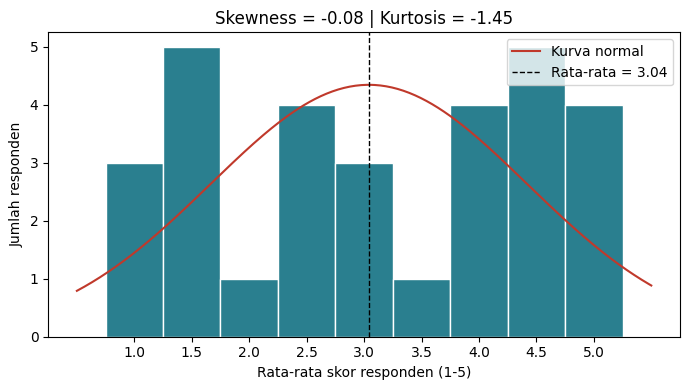

Rata-rata skor 3.04 (SD 1.38) | skewness -0.078 | kurtosis -1.453
Respon emosional


,STS,TS,N,S,SS
B1,4,1,0,9,16
B2,3,1,0,11,15
B3,3,2,0,9,16
B4,4,0,0,11,15
B5,3,1,0,6,20


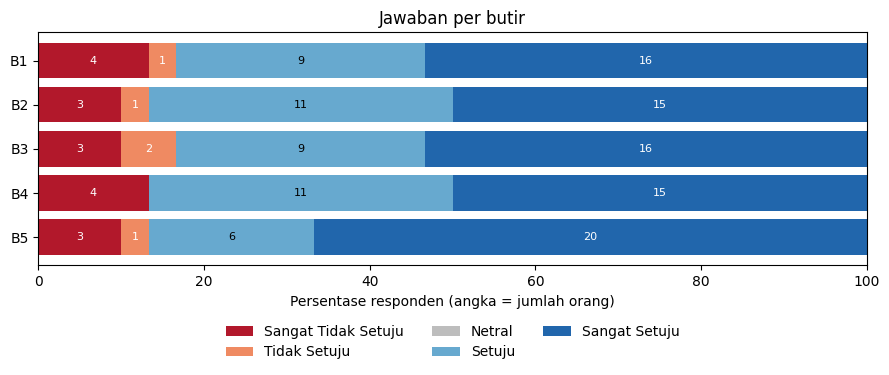

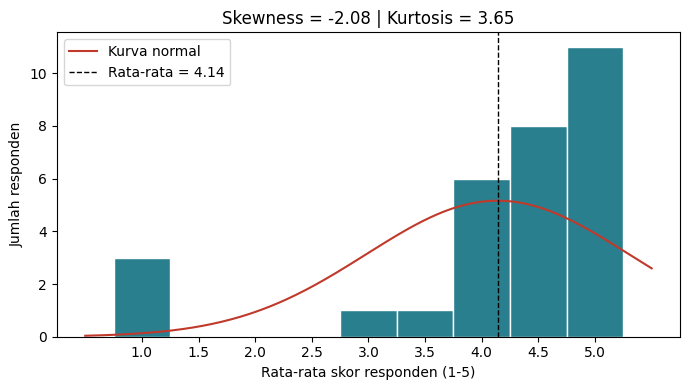

Rata-rata skor 4.14 (SD 1.16) | skewness -2.083 | kurtosis 3.646


In [17]:
import numpy as np
import matplotlib.pyplot as plt

def tabel_frekuensi(x):
    t = pd.DataFrame({lab: (x == v).sum() for v, lab in
                      zip(range(1, 6), ["STS", "TS", "N", "S", "SS"])})
    t.index = [f"B{i}" for i in range(1, x.shape[1] + 1)]
    return t

def grafik_batang(t):
    warna = ["#b2182b", "#ef8a62", "#bdbdbd", "#67a9cf", "#2166ac"]
    nama = ["Sangat Tidak Setuju", "Tidak Setuju", "Netral", "Setuju", "Sangat Setuju"]
    n = t.iloc[0].sum()
    fig, ax = plt.subplots(figsize=(9, 4))
    kiri = np.zeros(len(t))
    for lab, w, nm in zip(t.columns, warna, nama):
        persen = t[lab].values / n * 100
        ax.barh(t.index, persen, left=kiri, color=w, label=nm)
        for y, (p, k, j) in enumerate(zip(persen, kiri, t[lab].values)):
            if j > 0:
                ax.text(k + p / 2, y, int(j), ha="center", va="center", fontsize=8,
                        color="white" if lab in ("STS", "TS", "SS") else "black")
        kiri += persen
    ax.invert_yaxis(); ax.set_xlim(0, 100)
    ax.set_xlabel("Persentase responden (angka = jumlah orang)")
    ax.set_title("Jawaban per butir")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
    plt.tight_layout(); plt.show()

def histogram(x):
    skor = x.mean(axis=1)                         # rata-rata butir per responden
    sk = stats.skew(skor, bias=False)
    ku = stats.kurtosis(skor, bias=False)         # excess kurtosis
    lebar = 0.5
    tepi = np.arange(0.75, 5.5 + 1e-9, lebar)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(skor, bins=tepi, color="#2a7f8f", edgecolor="white")
    xs = np.linspace(0.5, 5.5, 300)
    ax.plot(xs, stats.norm.pdf(xs, skor.mean(), skor.std(ddof=1)) * len(skor) * lebar,
            color="#c0392b", label="Kurva normal")
    ax.axvline(skor.mean(), color="black", ls="--", lw=1, label=f"Rata-rata = {skor.mean():.2f}")
    ax.set_xticks(np.arange(1, 5.01, 0.5))
    ax.set_xlabel("Rata-rata skor responden (1-5)"); ax.set_ylabel("Jumlah responden")
    ax.set_title(f"Skewness = {sk:.2f} | Kurtosis = {ku:.2f}")
    ax.legend(); plt.tight_layout(); plt.show()
    return skor, sk, ku

for nama, daftar in dimensi_laporan.items():
    x = num[daftar]
    print(nama)
    t = tabel_frekuensi(x); display(t)
    grafik_batang(t)
    skor, sk, ku = histogram(x)
    print(f"Rata-rata skor {skor.mean():.2f} (SD {skor.std(ddof=1):.2f}) | skewness {sk:.3f} | kurtosis {ku:.3f}")